In [79]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [80]:
import sys
sys.path.append("../src")

In [81]:
DATA_DIR = "../data/troupe/TLS"

In [82]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  12


In [83]:
t_id = 9
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
# t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	295
Total number of nodes:	589
Rooted:	Yes
Most distant node:	ACCCTTGTCTGAGTCA-1
Max. distance:	0.993565


In [84]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, weight=node.dist)

    G.graph["root"] = node_ids[t]

    return G

In [85]:
T = ete_to_nx(t)
T

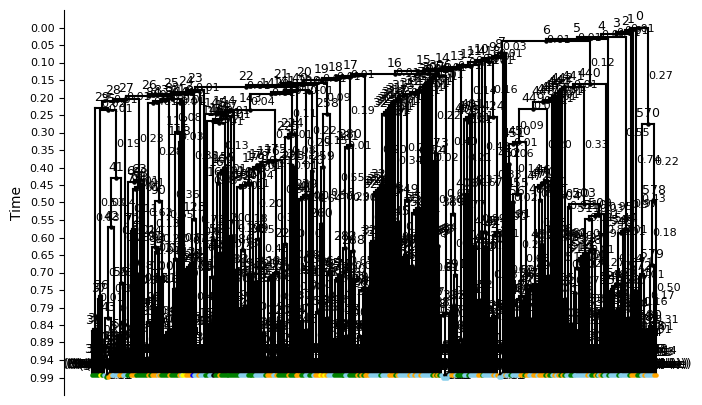

In [86]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'])

In [87]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [88]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [89]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9871282393092302 0.993564891953073


In [90]:
EPS = 1e-4
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [91]:
for u, v, d in T.edges(data=True):
    d['weight'] *= scale

In [92]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['weight']
        
        excess = dist - 1.0
        T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths

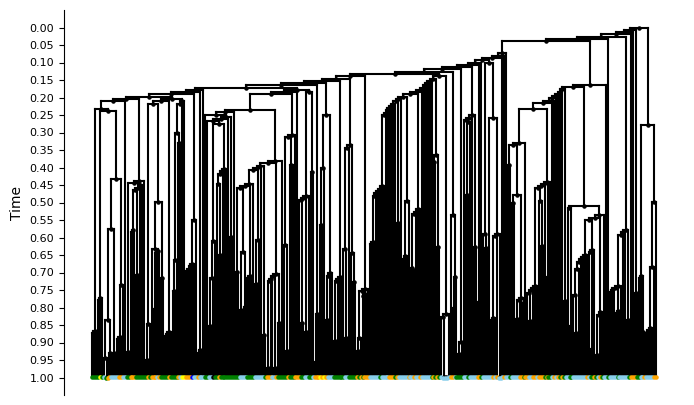

In [93]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [94]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [95]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999 1.0


## Differentiation Map from CARTA

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


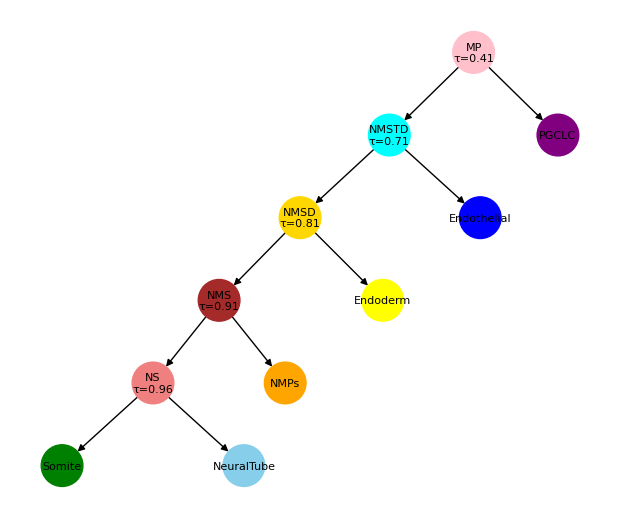

In [96]:
import string
from plotters import plot_differentiation_tree

diff_map_edges = [
    ("MP", "PGCLC"),
    ("MP", "NMSTD"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
]

a = 0.96
b = 0.05
c = 0.1
d = 0.1
e = 0.3

diff_times = {
    "MP":  a- b - c - d - e,
    "NMSTD": a - b - c - d,
    "NMSD": a - b - c,
    "NMS": a - b,
    "NS": a,
    "PGCLC": None,
    "Endothelial": None,
    "Endoderm": None,
    "NMPs": None,
    "Somite": None,
    "NeuralTube": None
}

diff_T = nx.DiGraph()


for k, v in diff_times.items():
    diff_T.add_node(k, diff_time=v)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

In [97]:
from likelihood import add_node_times
T = add_node_times(T, root=T.graph['root'])

In [98]:
rev_diff_T = diff_T.copy()
for n in diff_T.nodes():
    if diff_T.nodes[n]['diff_time'] is None: rev_diff_T.nodes[n]['diff_time'] = 0
    else: rev_diff_T.nodes[n]['diff_time'] = 1 - diff_T.nodes[n]['diff_time']

In [99]:
from likelihood import assign_states_to_internal_nodes

T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Children have > 1 types ['NMPs', 'Somite'] at 9.931689433773094e-05
Setting state for descendant 48 at 0.0 to ?
Setting state for descendant 47 at 0.0 to ?
Children have > 1 types ['NeuralTube', 'NMPs'] at 0.02688102477975851
Setting state for descendant 218 at 9.993834750410269e-05 to ?
Setting state for descendant 219 at 9.993834750410269e-05 to ?
Children have > 1 types ['NMPs', 'NS'] at 0.04974350611578382
Setting state for descendant 88 at 9.940701424637766e-05 to ?
Setting state for descendant 87 at 9.940701424637766e-05 to ?
Children have > 1 types ['NMPs', 'NS'] at 0.07091024764975629
Setting state for descendant 50 at 9.931689433761992e-05 to ?
Setting state for descendant 51 at 9.931689433761992e-05 to ?
Children have > 1 types ['NMPs', 'NS'] at 0.07140851891375244
Setting state for descendant 136 at 9.947617328487368e-05 to ?
Setting state for descendant 137 at 9.947617328487368e-05 to ?
Children have > 1 types ['NMPs', 'NS'] at 0.07641601116875207
Setting state for descenda

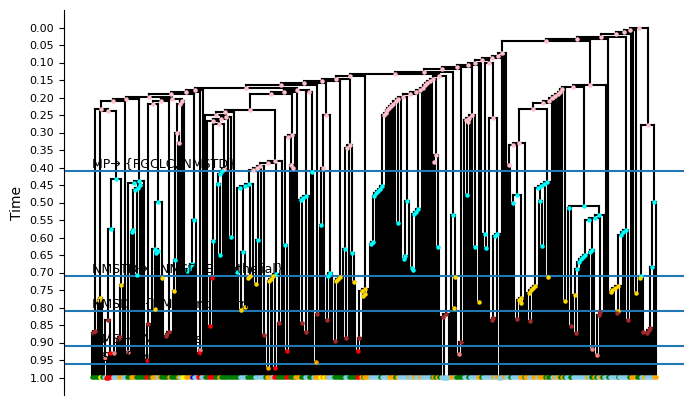

In [100]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [101]:
types = list(diff_T.nodes())

transition_maps = [
    (i, succ)
    for i in diff_T.nodes()
    if (succ := list(diff_T.successors(i)))
]

print(types)
print(transition_maps)

['MP', 'NMSTD', 'NMSD', 'NMS', 'NS', 'PGCLC', 'Endothelial', 'Endoderm', 'NMPs', 'Somite', 'NeuralTube']
[('MP', ['PGCLC', 'NMSTD']), ('NMSTD', ['NMSD', 'Endothelial']), ('NMSD', ['NMS', 'Endoderm']), ('NMS', ['NS', 'NMPs']), ('NS', ['Somite', 'NeuralTube'])]


In [102]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

from likelihood import calculate_likelihood_of_tree, calculate_log_likelihood_of_tree


MAX_DEATH = 1.0
MAX_BIRTH = 10.0


def unpack_params(theta):

    k = 0

    # -------------------------
    # Death rates: (0, 1)
    # -------------------------
    death = {}
    for t in types:
        death[t] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Birth rates: (death, 10)
    # -------------------------
    birth = {}
    for t in types:
        birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Transition matrix
    # -------------------------
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:

        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)

        # numerical stability
        logits -= np.max(logits)

        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return birth, death, Q


def neg_log_likelihood(theta, cell_lineage_T, diff_T, sampling_rate=1.0):

    birth, death, Q = unpack_params(theta)

    try:

        p, _, _ = calculate_log_likelihood_of_tree(
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            cell_lineage_T=cell_lineage_T,
            diff_T=diff_T
        )

    except Exception:
        return 1e300
    
    return -np.log(p)


def pack_initial():

    params = []

    # initial death parameters
    for t in types:
        params.append(0.0)  # sigmoid(0)=0.5 → death ≈ 0.5

    # initial birth parameters
    for t in types:
        params.append(0.0)  # sigmoid(0)=0.5 → birth ≈ halfway to 10

    # transition logits
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)

    return np.array(params)


def find_params(cell_lineage_T, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(cell_lineage_T, diff_T, 1.0),
        method="L-BFGS-B"
    )

    birth, death, Q = unpack_params(result.x)

    return birth, death, Q

In [104]:
birth_rates, death_rates, Q = find_params(T, rev_diff_T)
birth_rates, death_rates, Q

({'MP': np.float64(5.25),
  'NMSTD': np.float64(5.25),
  'NMSD': np.float64(5.25),
  'NMS': np.float64(5.25),
  'NS': np.float64(5.25),
  'PGCLC': np.float64(5.25),
  'Endothelial': np.float64(5.25),
  'Endoderm': np.float64(5.25),
  'NMPs': np.float64(5.25),
  'Somite': np.float64(5.25),
  'NeuralTube': np.float64(5.25)},
 {'MP': np.float64(0.5),
  'NMSTD': np.float64(0.5),
  'NMSD': np.float64(0.5),
  'NMS': np.float64(0.5),
  'NS': np.float64(0.5),
  'PGCLC': np.float64(0.5),
  'Endothelial': np.float64(0.5),
  'Endoderm': np.float64(0.5),
  'NMPs': np.float64(0.5),
  'Somite': np.float64(0.5),
  'NeuralTube': np.float64(0.5)},
               MP  NMSTD  NMSD  NMS   NS  PGCLC  Endothelial  Endoderm  NMPs  \
 MP           0.0    0.5   0.0  0.0  0.0    0.5          0.0       0.0   0.0   
 NMSTD        0.0    0.0   0.5  0.0  0.0    0.0          0.5       0.0   0.0   
 NMSD         0.0    0.0   0.0  0.5  0.0    0.0          0.0       0.5   0.0   
 NMS          0.0    0.0   0.0  0.0  0.5 

### debug

In [105]:
likelihood, L, U = calculate_likelihood_of_tree(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=1.0,
    transition_probabilities=Q,
    cell_lineage_T=T,
    diff_T=rev_diff_T
)
likelihood

np.float64(0.0)

In [106]:
from collections import defaultdict

edge_ml = defaultdict(float)

for (u, v, t, s), val in L.items():
    edge_ml[(u, v)] = max(edge_ml[(u, v)], float(val))

zero_ml_edges = {e for e, v in edge_ml.items() if v == 0}

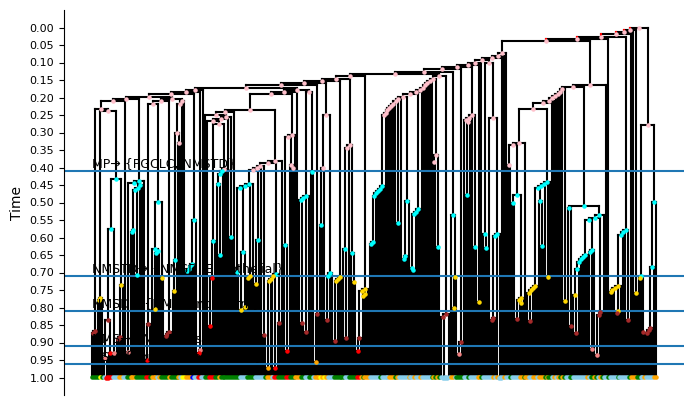

In [107]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T, red_edges=zero_ml_edges)

In [108]:
T.nodes[6]

{'name': 'node_52',
 'dist': 0.006434899604547414,
 'is_leaf': False,
 'T': 0.9608906174060516,
 'state': 'MP'}

In [109]:
for child in T.successors(6):
    print(child, T.nodes[child], edge_ml[6, child])

7 {'name': 'node_156', 'dist': 0.034542757354057506, 'is_leaf': False, 'T': 0.9259009355157919, 'state': 'MP'} 1.474243528867839e-295
440 {'name': 'node_53', 'dist': 0.12270407298583258, 'is_leaf': False, 'T': 0.836598962388269, 'state': 'MP'} 2.529259076497386e-69


In [110]:
edge_ml[5, 6]

0.0

In [111]:
for e1, e2 in T.edges():
    if (e1, e2) in zero_ml_edges: 
    # and T.nodes[e2]['T'] == 0:
        print(e1, e2, T.nodes[e1]['T'], T.nodes[e2]['T'], T.nodes[e2]['state'])

0 1 1 0.9934816896944862 MP
1 2 0.9934816896944862 0.9869633892002051 MP
2 3 0.9869633892002051 0.9804451163936484 MP
3 4 0.9804451163936484 0.9739269274681001 MP
4 5 0.9739269274681001 0.9674087736681898 MP
5 6 0.9674087736681898 0.9608906174060516 MP


In [112]:
# for e1, e2 in T.edges():
#     if T.nodes[e2]['state'] == "?":
#         for k, v in L.items():
#             e_1, e_2, t, s = k
#             if e_1 == e1 and e_2 == e2:
#                 print(k, v)

for e1, e2 in T.edges():
    for k, v in L.items():
        e_1, e_2, t, s = k
        if e1 == e_1 and e2 == e_2 and v == 0 and T.nodes[e2]['T'] == 0:
            print(k, v, T.nodes[e2]['state'], T.nodes[e2]['T'])

(383, 384, 9.893022021001396e-05, 'Somite') 0.0 NeuralTube 0.0
(383, 384, 9.893022021001396e-05, 'NMPs') 0.0 NeuralTube 0.0
(383, 384, 9.893022021001396e-05, 'PGCLC') 0.0 NeuralTube 0.0
(383, 384, 9.893022021001396e-05, 'Endoderm') 0.0 NeuralTube 0.0
(383, 384, 9.893022021001396e-05, 'Endothelial') 0.0 NeuralTube 0.0
(385, 386, 9.893022021001396e-05, 'Somite') 0.0 NeuralTube 0.0
(385, 386, 9.893022021001396e-05, 'NMPs') 0.0 NeuralTube 0.0
(385, 386, 9.893022021001396e-05, 'PGCLC') 0.0 NeuralTube 0.0
(385, 386, 9.893022021001396e-05, 'Endoderm') 0.0 NeuralTube 0.0
(385, 386, 9.893022021001396e-05, 'Endothelial') 0.0 NeuralTube 0.0
(385, 387, 9.893022021001396e-05, 'Somite') 0.0 NeuralTube 0.0
(385, 387, 9.893022021001396e-05, 'NMPs') 0.0 NeuralTube 0.0
(385, 387, 9.893022021001396e-05, 'PGCLC') 0.0 NeuralTube 0.0
(385, 387, 9.893022021001396e-05, 'Endoderm') 0.0 NeuralTube 0.0
(385, 387, 9.893022021001396e-05, 'Endothelial') 0.0 NeuralTube 0.0
(434, 435, 9.9510082479215e-05, 'Somite') 0

### Considering all trees together

In [113]:
Ts = []

for t_id in range(len(data)):
    t = data[t_id]
    T = ete_to_nx(t)
    Ts.append(T)

In [114]:
## scale edges
EPS = 1e-4

for T in Ts:
    leaves = [n for n, d in T.out_degree() if d == 0]
    # If edges have weight attribute 'length' or similar
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1
    for u, v, d in T.edges(data=True):
        d['weight'] *= scale
    
    for leaf in leaves:
        dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
        
        if dist > 1.0:
            parent = list(T.predecessors(leaf))[0]
            
            edge_length = T[parent][leaf]['weight']
            
            excess = dist - 1.0
            T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths
        

In [115]:
## add node times and assign internal states
for i, T in enumerate(Ts):
    print('='*50)
    print('Processing tree', i)
    print('='*50)
    T = add_node_times(T, root=T.graph['root'])
    T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Processing tree 0
Children have > 1 types ['NMPs', 'Somite'] at 0.015065184919464403
Setting state for descendant 276 at 0.007532592399324911 to ?
Setting state for descendant 277 at 0.007532592399324911 to ?
Children have > 1 types ['NMPs', 'Somite'] at 0.015065185015963434
Setting state for descendant 208 at 0.007532592495823942 to ?
Setting state for descendant 209 at 0.007532592495823942 to ?
Children have > 1 types ['NeuralTube', 'Somite'] at 0.015065185348234977
Setting state for descendant 161 at 0.007532592828095486 to ?
Setting state for descendant 162 at 0.007532592828095486 to ?
Children have > 1 types ['Endothelial', 'NMPs'] at 0.015065185435983008
Setting state for descendant 401 at 0.007532592915843517 to ?
Setting state for descendant 402 at 0.007532592915843517 to ?
Children have > 1 types ['NeuralTube', 'Somite'] at 0.015065186133222608
Setting state for descendant 14 at 0.007532593613083116 to ?
Setting state for descendant 15 at 0.007532593613083116 to ?
Children hav

Drawing tree 0


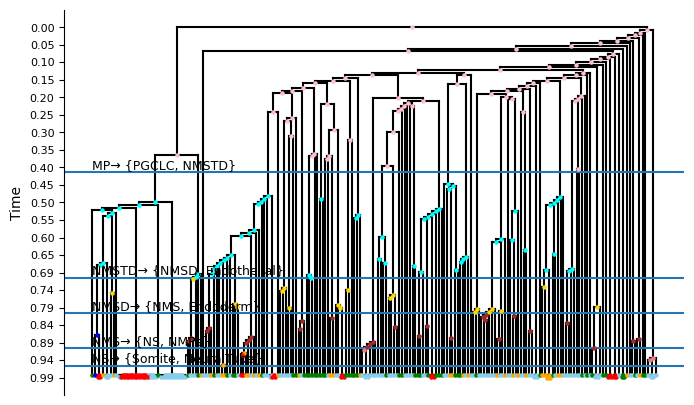

Drawing tree 1


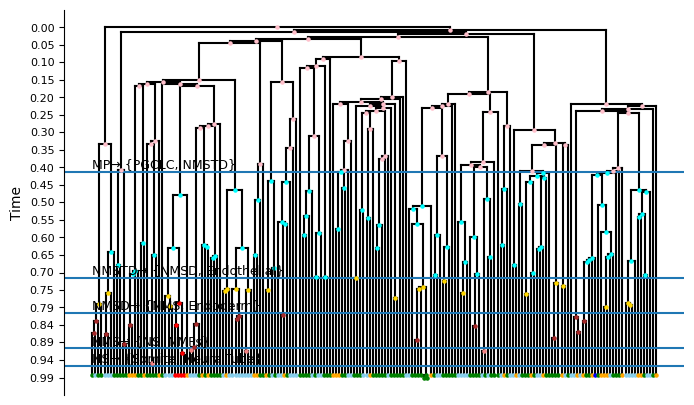

Drawing tree 2


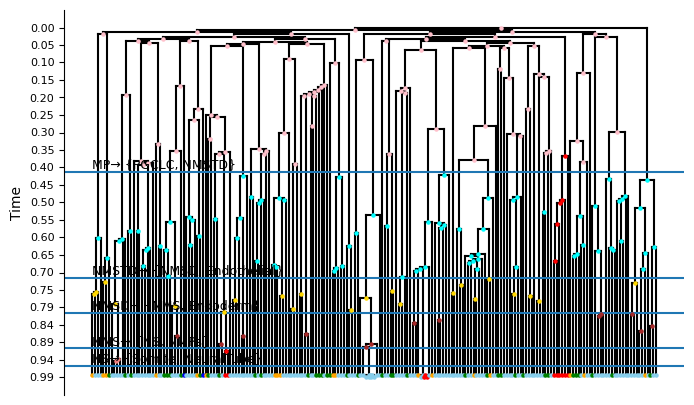

Drawing tree 3


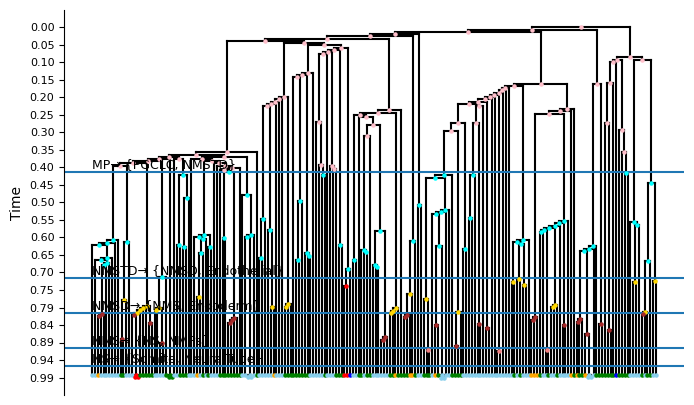

Drawing tree 4


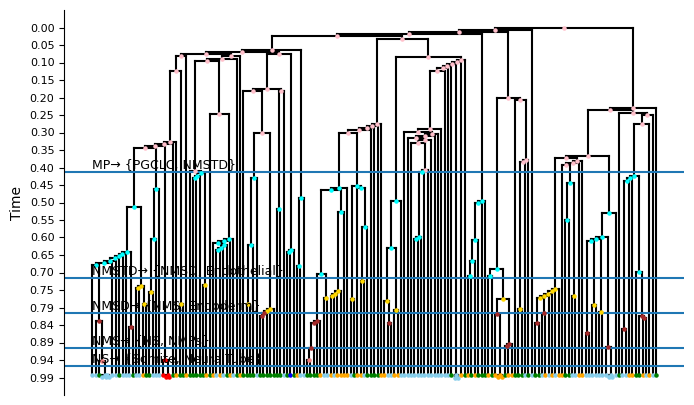

Drawing tree 5


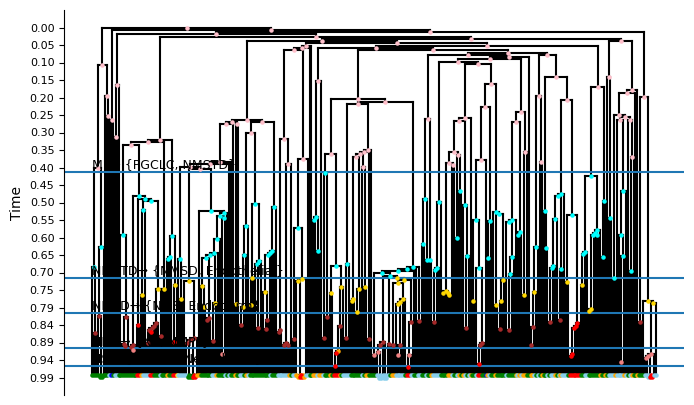

Drawing tree 6


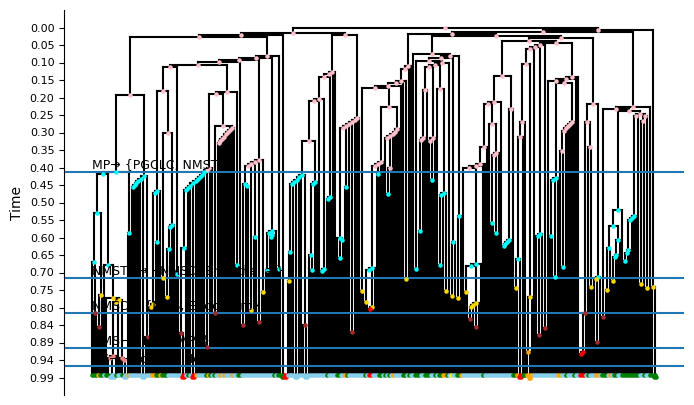

Drawing tree 7


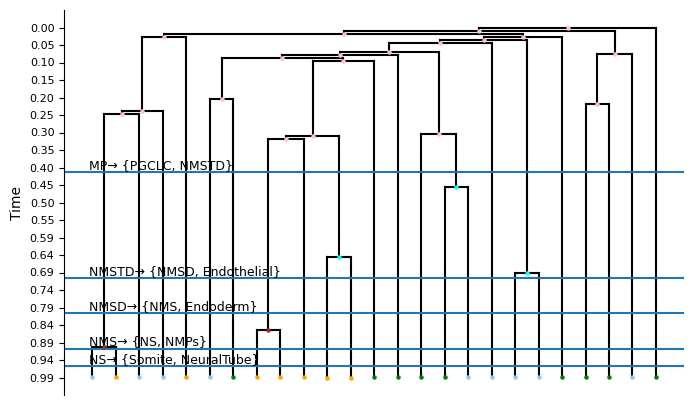

Drawing tree 8


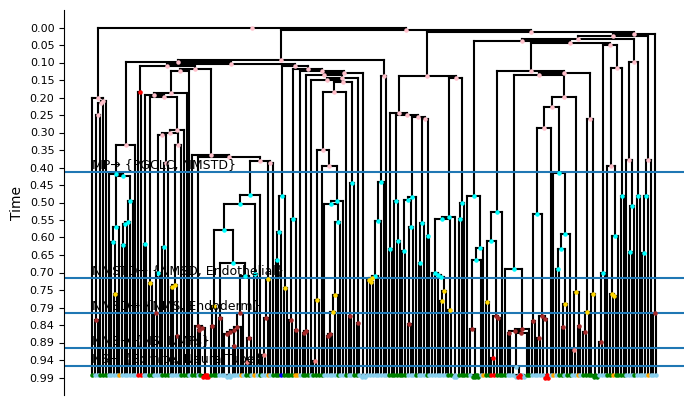

Drawing tree 9


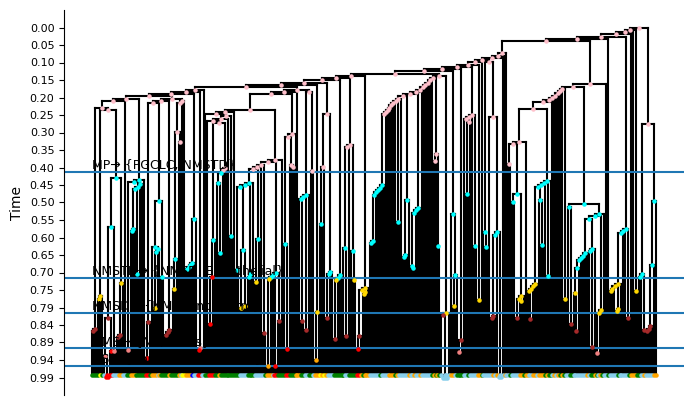

Drawing tree 10


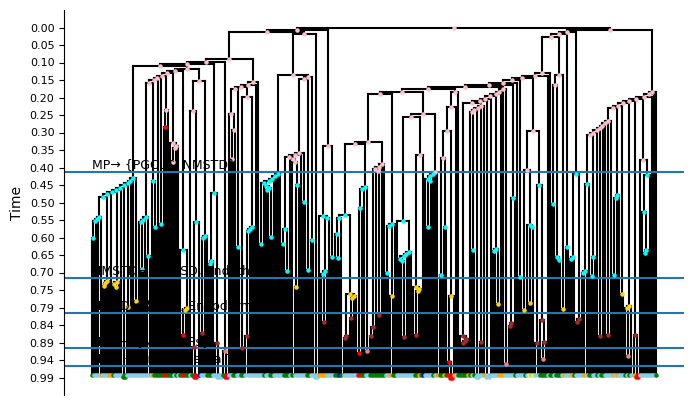

Drawing tree 11


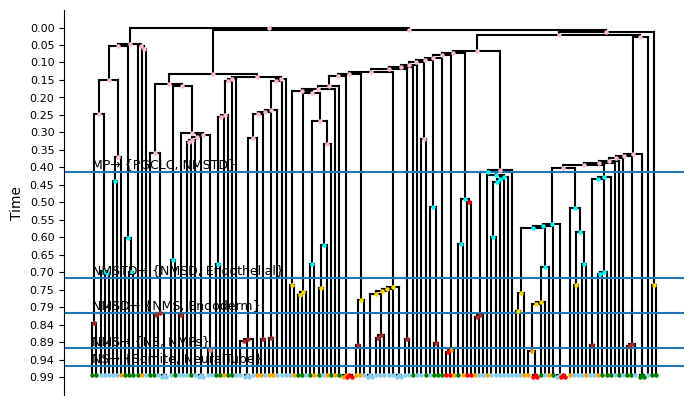

In [116]:
## draw trees
for i, T in enumerate(Ts):
    print('='*50)
    print('Drawing tree', i)
    print('='*50)
    draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [117]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

from likelihood import calculate_likelihood_of_tree, calculate_log_likelihood_of_tree


MAX_DEATH = 1.0
MAX_BIRTH = 10.0


def unpack_params(theta):

    k = 0

    # -------------------------
    # Death rates: (0, 1)
    # -------------------------
    death = {}
    for t in types:
        death[t] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Birth rates: (death, 10)
    # -------------------------
    birth = {}
    for t in types:
        birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Transition matrix
    # -------------------------
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:

        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)

        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return birth, death, Q


def neg_log_likelihood(theta, trees, diff_T, sampling_rate=1.0):

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for cell_lineage_T in trees:

        try:
            p, _, _ = calculate_likelihood_of_tree(
                birth_rates=birth,
                death_rates=death,
                sampling_rate=sampling_rate,
                transition_probabilities=Q,
                cell_lineage_T=cell_lineage_T,
                diff_T=diff_T
            )
        except Exception:
            return 1e300

        total_nll += -np.log(p)

    return total_nll


def pack_initial():

    params = []

    # death parameters
    for t in types:
        params.append(0.0)

    # birth parameters
    for t in types:
        params.append(0.0)

    # transition logits
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)

    return np.array(params)


def find_params(trees, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T, 1.0),
        method="L-BFGS-B"
    )

    print(result)

    birth, death, Q = unpack_params(result.x)

    return birth, death, Q

In [118]:
birth_rates, death_rates, Q = find_params(Ts[:9] + Ts[10:], rev_diff_T)
birth_rates, death_rates, Q

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 812.6888241300508
        x: [-5.619e+00  4.088e+00 ... -1.956e-01  3.905e-01]
      nit: 74
      jac: [ 2.901e-02 -6.645e-02 ...  1.663e-01  9.858e-01]
     nfev: 4125
     njev: 125
 hess_inv: <32x32 LbfgsInvHessProduct with dtype=float64>


({'MP': np.float64(5.338560018155717),
  'NMSTD': np.float64(2.8871431468380617),
  'NMSD': np.float64(1.5851830775617115),
  'NMS': np.float64(1.0776122216282837),
  'NS': np.float64(0.42670941757326003),
  'PGCLC': np.float64(4.226195891665445),
  'Endothelial': np.float64(0.9288914562554588),
  'Endoderm': np.float64(4.93272400047419),
  'NMPs': np.float64(0.25001351750441664),
  'Somite': np.float64(0.9462153357156354),
  'NeuralTube': np.float64(3.8639177225673054)},
 {'MP': np.float64(0.003613841777055169),
  'NMSTD': np.float64(0.9835061392654767),
  'NMSD': np.float64(0.9767951981219247),
  'NMS': np.float64(0.9791653430701655),
  'NS': np.float64(0.4267036750214272),
  'PGCLC': np.float64(0.6181893607296869),
  'Endothelial': np.float64(0.8798677658416767),
  'Endoderm': np.float64(0.575814353535035),
  'NMPs': np.float64(0.24999718650900665),
  'Somite': np.float64(0.9458305320585586),
  'NeuralTube': np.float64(0.9873188619631891)},
               MP  NMSTD      NMSD  NMS   

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


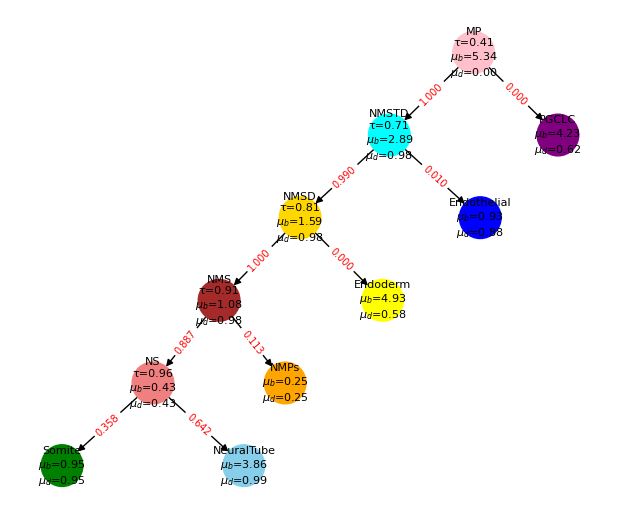

In [119]:
plot_differentiation_tree(diff_T, birth_rates, death_rates, transition_probabilities=Q)